### MATH2504 S2, 2025, Project 1 - MATH2504 - 2025 Submission

Student name: Sebastian Philpott

Student ID: s4696048

GitHub repo: https://github.com/sebastianphilpott1-maker/Sebastian-Philpott-2504-2025-PROJECT2

# Question 1

Some features that are not captured by the model include but is not limited to:

1. Rides being down for maintenance (Could weight this by a probability of ride i being operational)
2. Does not consider temporary ride malfunctions that may delay processing
3. Travel times between rides (internal arrivals) is not captured. Right now the model assumes instaneous arrivals

Some featues of the model that are unrealistic include but is not limited to:

1. Repeating myself but instaneous travel times are unrealistic
2. It is not explicitly stated but something that may be unrealistic is the binary choice between joining another queue or leaving. Many people at theme parks don't just do these two things.
3. Instantaneous modulation changes affecting processing speeds. I find it staggeringly hard to believe that any theme park on a whim can instantly speed up all queues by a flat rate. This scaling of processing speed should probably be continuous over range
4. The arrivals are a little unrealistic since over the course of a day, arrivals will surge in particular times given people are at work, weather etc

In addressing if this model is useful for assessing congestion at the park, I would say it is to some extent. It is, after all, only a simulation, and so results from the simulation could prove to be a good useful or general guide but concrete decisions should not be made from simulation results. They should inform decisions.

We would use such a model in the context of a park when weather conditions are good, rides have high operational efficiency and there is a strong turnout of customers projected to simulate what a busy day may look like and how queue sizes may vary over the day.


# Question 2

Below is the plot for the fast case

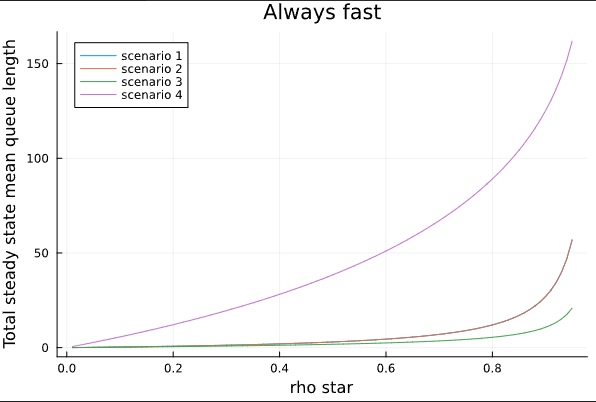

The slow case:

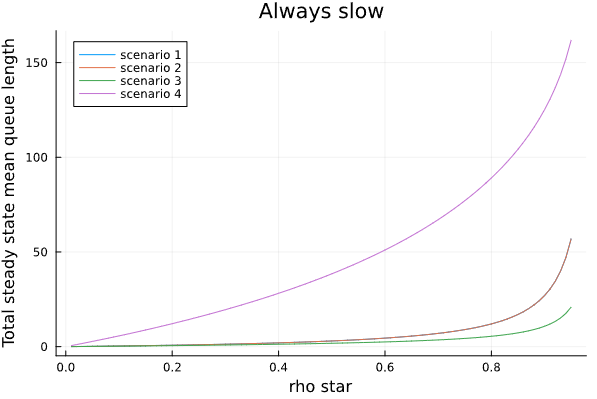

The always fast case:

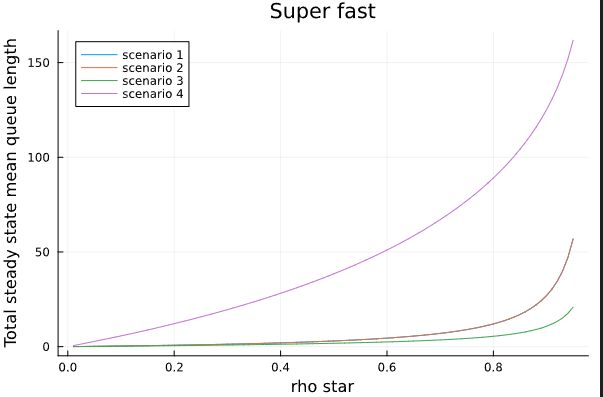

# Question 3

Below is simulation net trace and scenario 1 with rho star set to 0.8, gamma_1 set to 0.1 and R1 set to 0.67. Note that I am just now reading on the edboard that gamma 1 should be 10^-8 for the first three scenarios. I might be dumb but I do not see where that is stated to be a requirement:

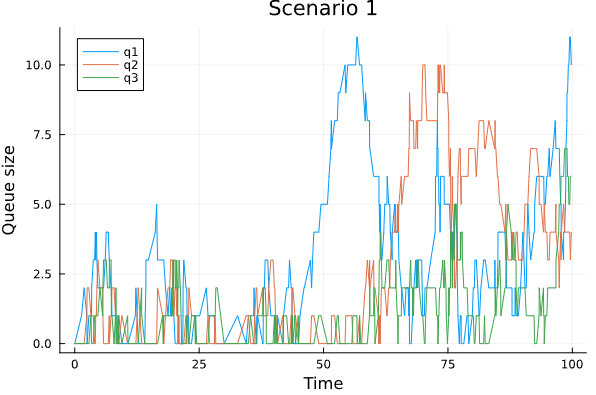

Below is simulation net trace and scenario 2 with rho star set to 0.8, gamma_1 set to 0.1 and R1 set to 0.67:

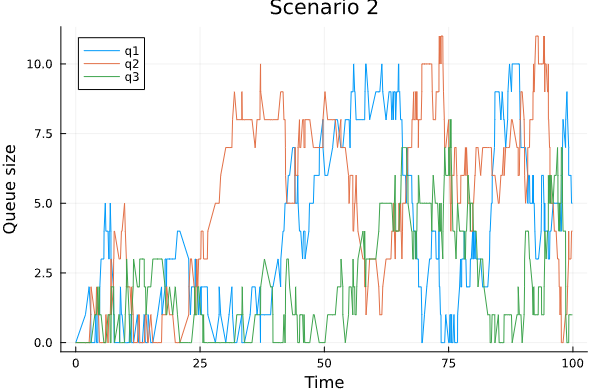

Below is simulation net trace and scenario 3 with rho star set to 0.8, gamma_1 set to 0.1 and R1 set to 0.67:

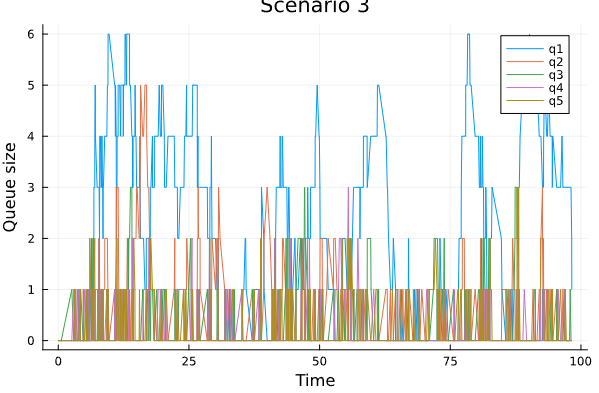

# Question 4

## Question 4.1

For the always slow case with gamma 1 set to 10^-8 and R1 set to 1 - 10^-8 and kappa = 2.0 we generated the following plots:

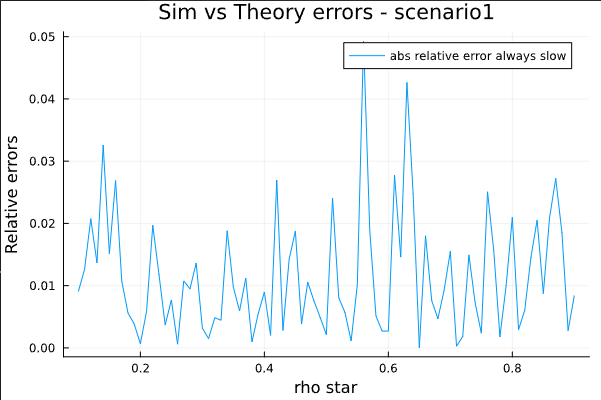


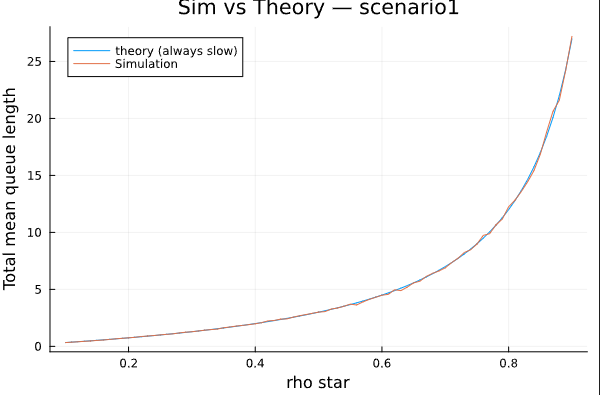


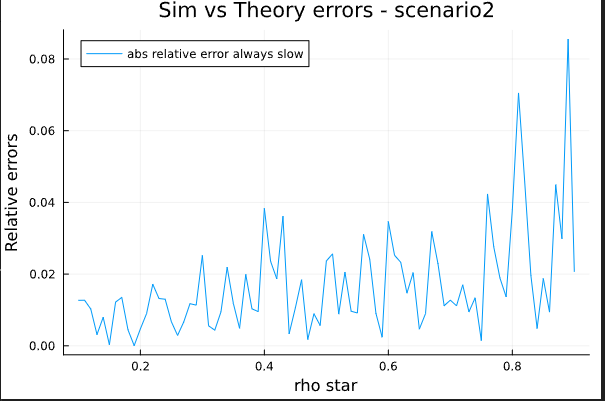


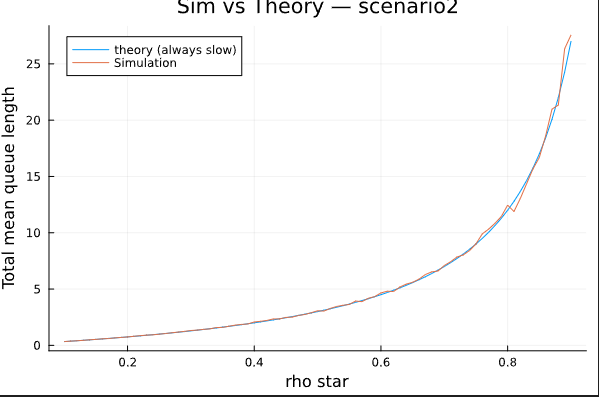


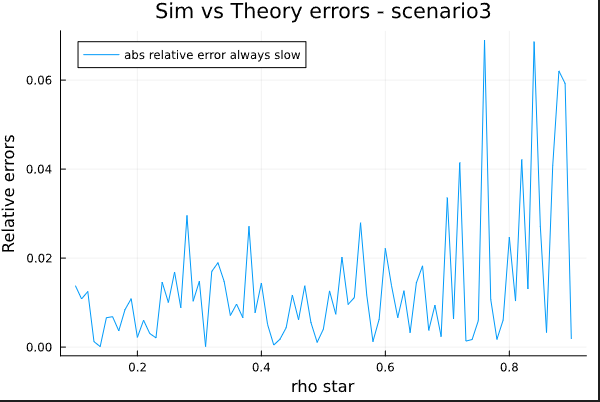


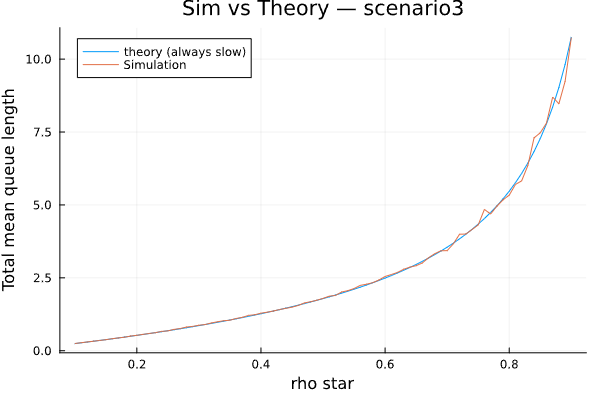


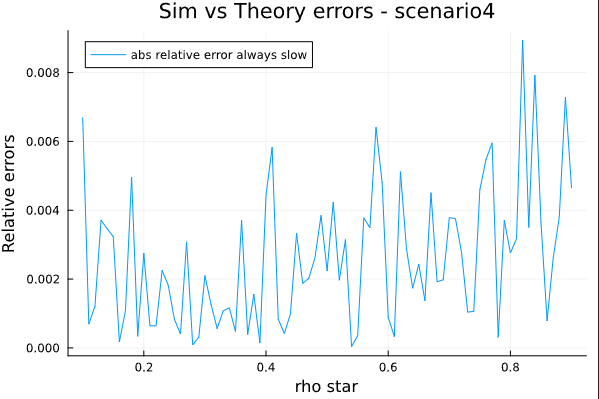


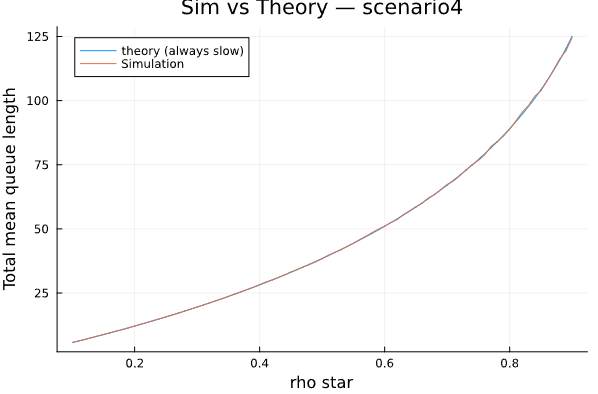



Max_time was set to 10^5 for computational time concerns. There is likely ineffficiency in my code. You can see in the code base that the jackson_thing function calculates the theoretical mean without adjusting the mu vector since in the always slow case no adjustment is required. There exists virtually no modulation.

It is worth noting - I think - that the graphs for scenario 4 look to be the most consistent. This is likely because the code ran longer with more information available to it and so the variance is more likely to decrease over time, thus better approximating the theoretical mean for the simulated run.

## Question 4.2

For the always fast case with gamma 1 set to 1000.0 and R1 set to 10^-8 and kappa = 2.0 we generated the following plots:

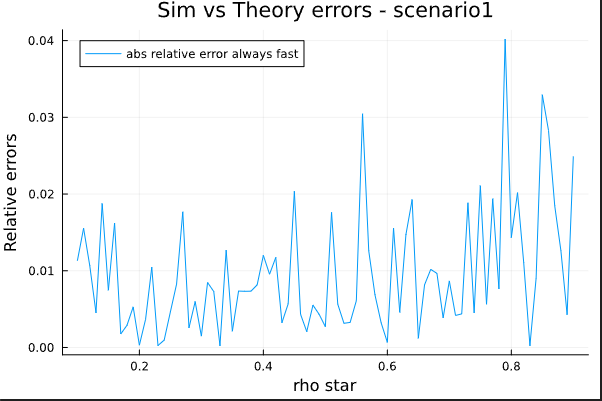 


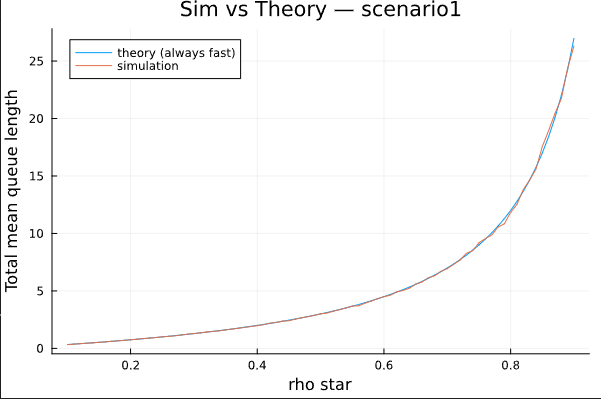 


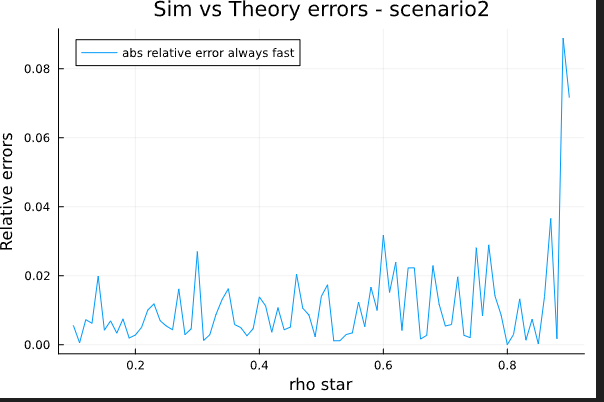 


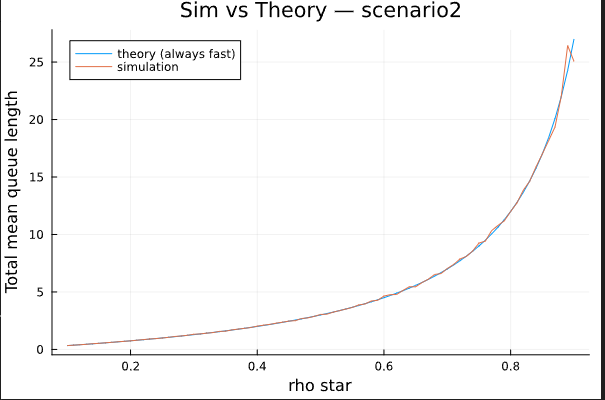 


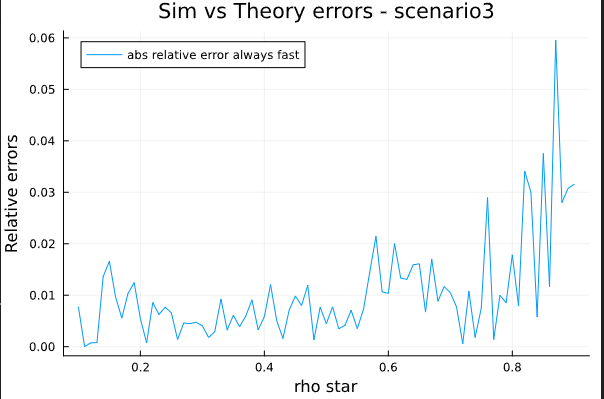 


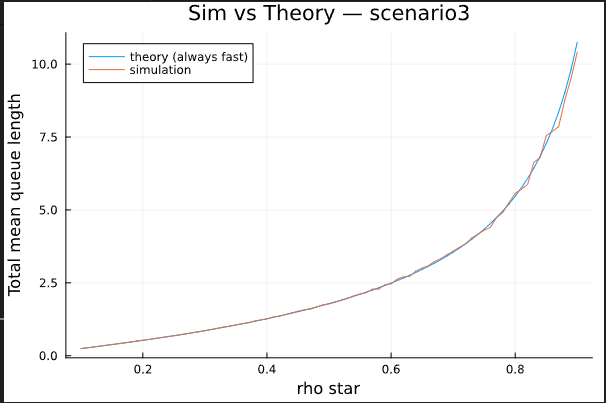 


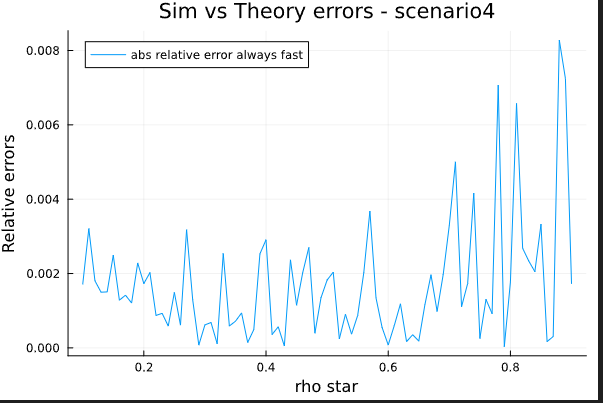 


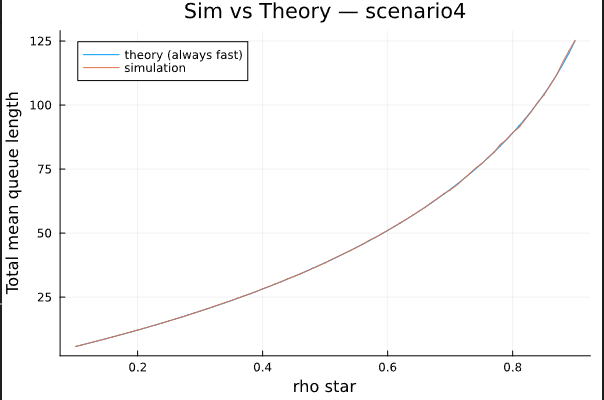


### Comments

A "crazier" gamma 1 value was chosen to attempt to exacerbate the effect of the simulation, however since we are in the always fast case and the theoretical mean computed adjusts for this scaling speed, we actually expect total mean queue sizes to coincide in both cases.

Again, we observe the same pattern with the fourth scenario having more consistent traces.

## Question 4.3

For the always fast case with gamma 1 set to 10.0 and R1 set to 0.50 and kappa = 2.0 we generated the following plots:

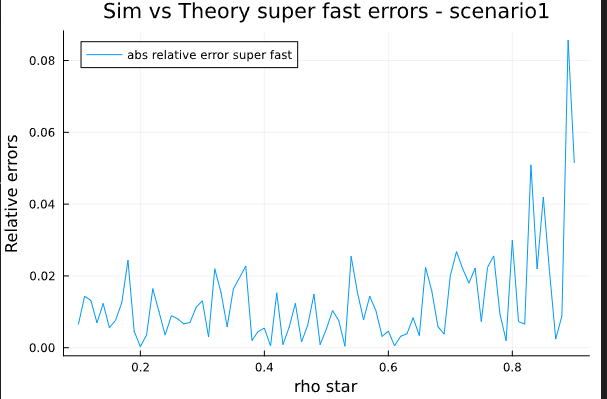 


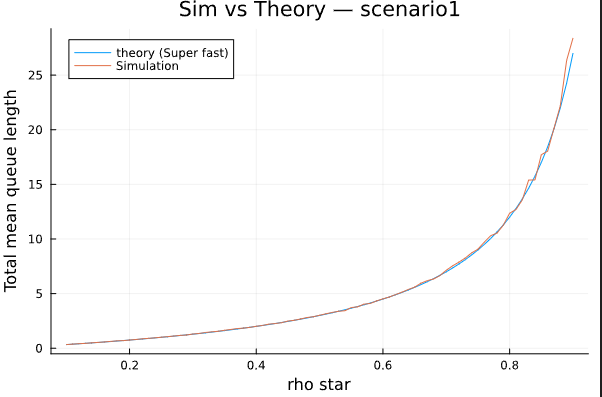 


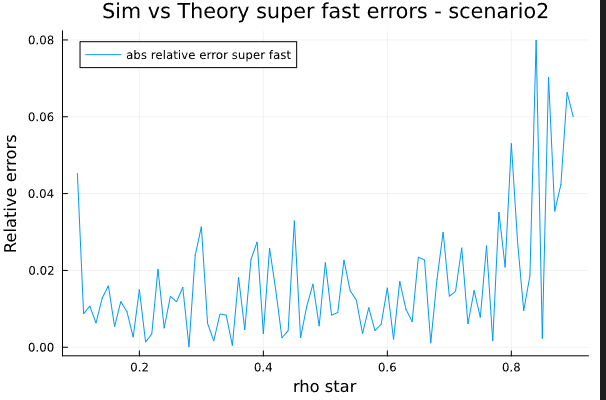 


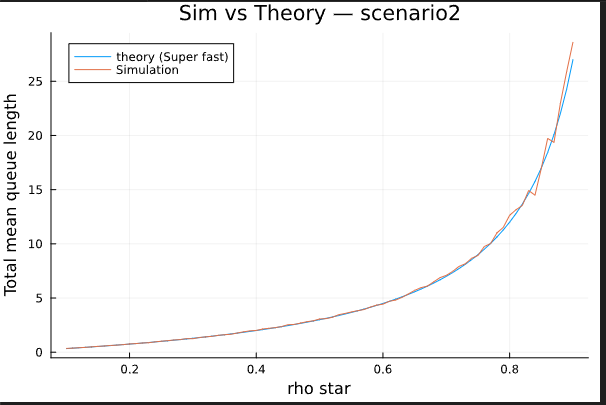 


![scen_3 trace.png](<attachment:scen_3 trace.png>)


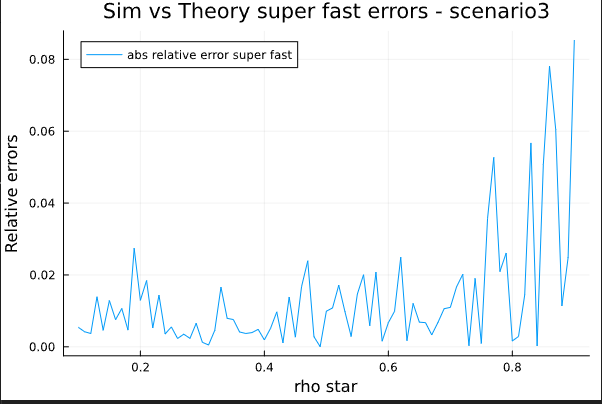 


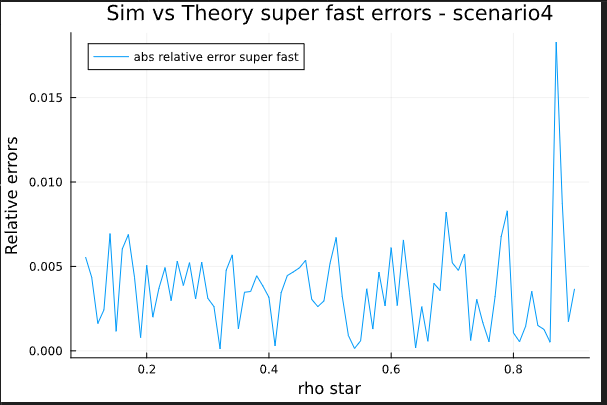 


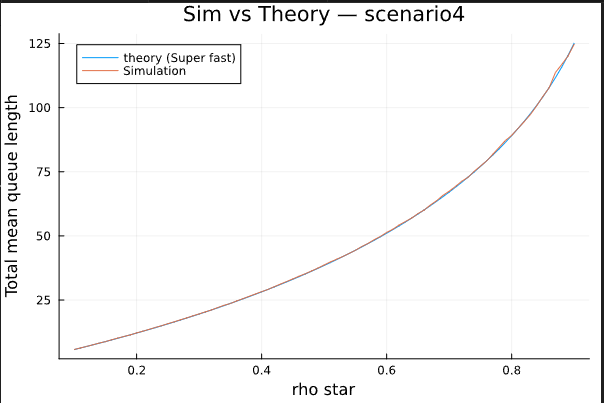


### Comments

In this set of tests, we set R1 to be 0.5 since I thought it would be cool if the system spent an equal amount of time in each state, then over the long run, in a test where we scale the rate mu by calculating the average service rate and using that to calculate the theoretical mean, we could - maybe, I'm still not convinced - confirm the accuracy of our script. Indeed, for our simulation, we see quite a strong trace of the theoretical and simulation and the relative errors stay somewhat controlled over the course of the run.

(Side note, I tried to run this code with max_time = 10^6 and it ran for 2 hours and this is what prompted me to reduce the time for all tests)
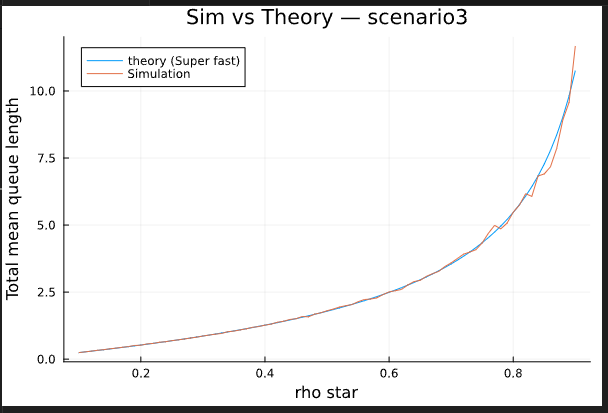

# Question 4 Final comment

In most of the graphs for all tests, there seems to be a spike in relative errors towards the tail end of the sim. Given that it is consistent across all tests, it is likely to be an error within the simulated code in not handling final events correctly.

This could manifest itself in stopping the simulation before processing jobs that have a modulation change, or just incorrect recording logic that breaks inbetween time intervals. Though, the true nature of these spikes I do not know if it is a feature of the simulation itself, or my code.


Also, rerunning test 1 with warm up time and max run time scaled by an order of magnitude, we observe the following relative error and trace graphs. Here we can see that after tweaking these variables, there is a noticable change however statistical inference would need to be performed to establish if this relationship is causal. All we can say as of now is that there may be a relationship.

After all that yapping, we can see the provided graphs with longer run times in the always slow case lead to lower relative errors and stronger estimations of the theoretical trajectories of the simulated scenarios.


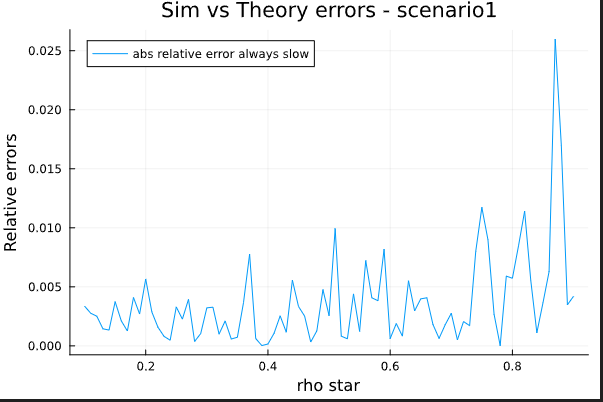 


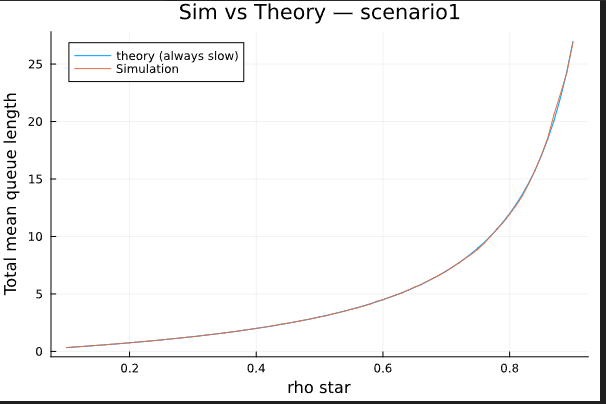


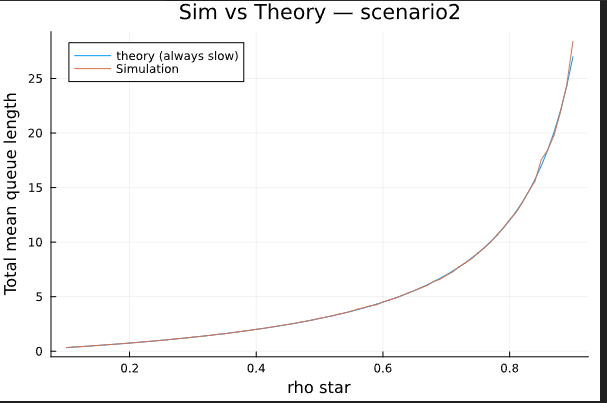


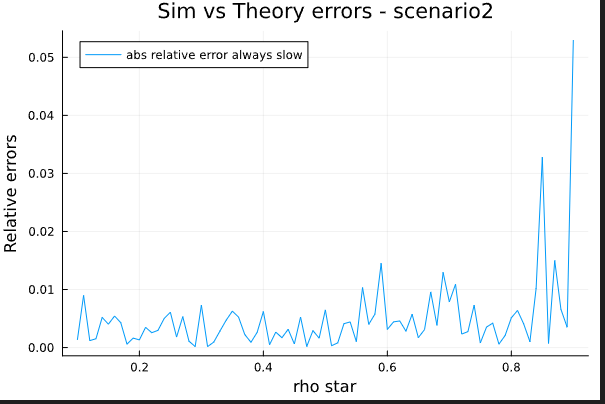


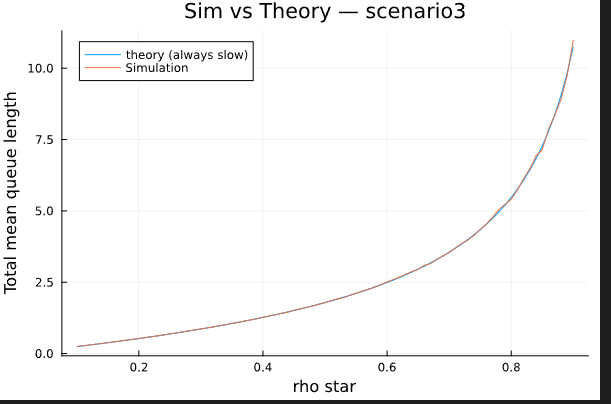


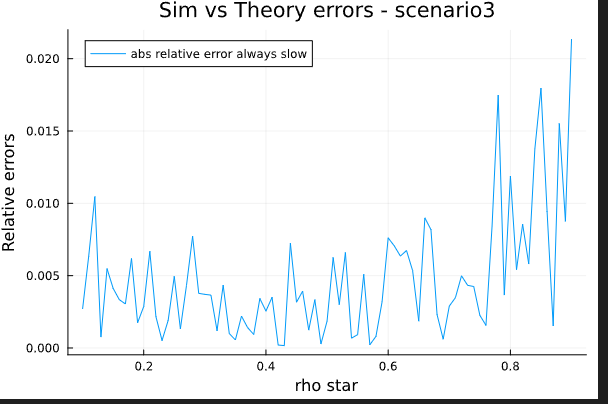


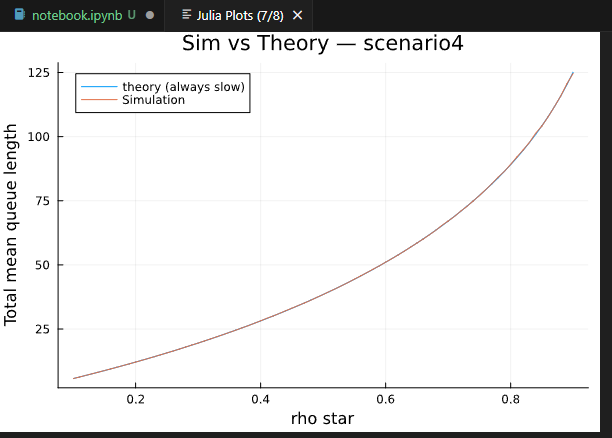


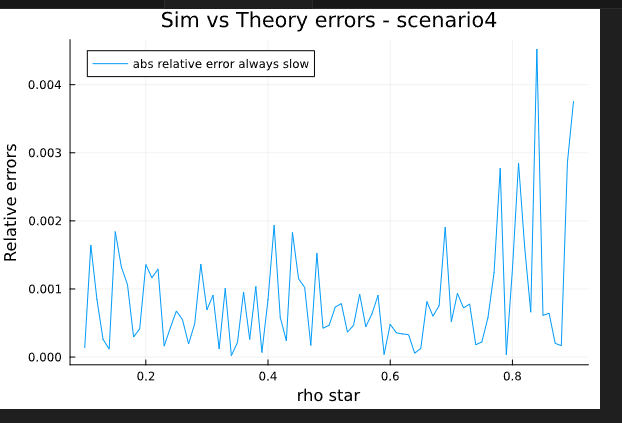


# Question 5

For the plots generated below, I had gamma at 0.10, kappa at 2.0 and the R1 vals at 0.1, 0.2, 0.3, 0.4, 0.5 and 0.9. Max time was 10^5 and warm up was 10^3


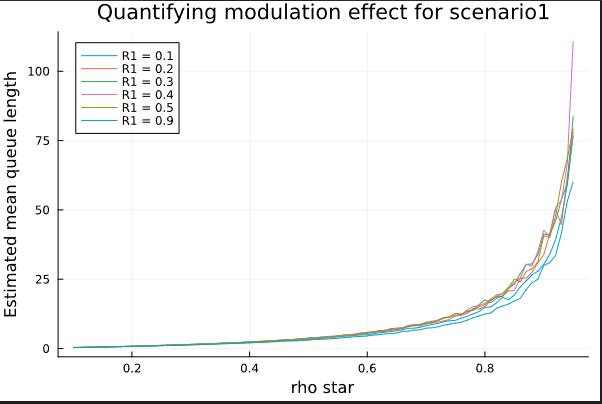 


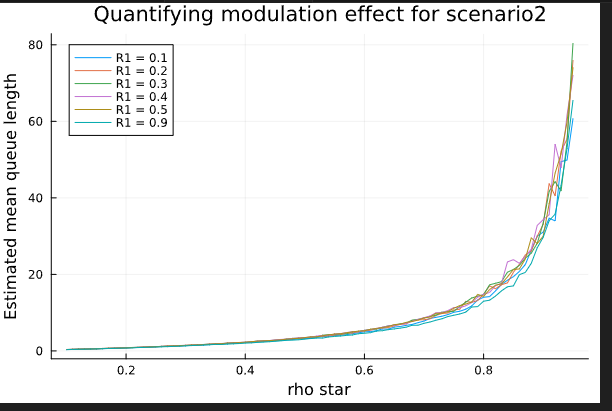 


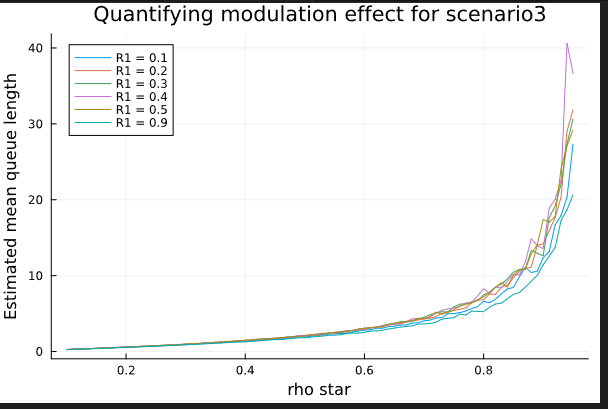



## Discussion

Firstly, none of these results really match what I expected and it is too late to fix my code. Alternatively I could be plotting something incorrectly or have forgotten to average something. Possibilities are endless. The mismatch I have found is that we probably expect lower R1 values to correspond to smaller mean queue lengths. However, this is not the case.

Maybe, just maybe, if we squint and zoom in and let our eyes betray us we could potentially say that there is a slight trend that lower R1 values give us this? But it doesn't really look like.

To show that I actually understand it though, lower R1 value means the proportion of time we spend in a slow state is lower. That means we spend more time in fast state, and so more time in fast state means jobs are more frequently sampled with quicker service rates. The biggest doozy is when R1 is 0.9 it is the fastest. Maybe in my code somewhere I have reversed this logic but it is too late for me.

Reversed speed up logic is what I'd put my money on being the culprit (unless this is how I learn I am colour blind and I am just reading the legend wrong).

I'd fix the code and regenerate some plots but it takes 5 years to regenerate the plots at these run times. Lastly, I was finishing this at the last minute which wouldn't have been an issue if plots didn't take 5 years to generate. First three are given but yeah.